# IND320 Dashboard

Denne notebooken dokumenterer del 2 av IND320-prosjektet: henting av data fra NVE og ENTSO-E, lagring i Cassandra og MongoDB, og oppdatering av Streamlit-appen.

## Lenker

- GitHub-repository (del 2 ligger på branchen part2): https://github.com/Kaja321/ind320-dashboard-kaja321/tree/part2
- Publisert Streamlit-app: https://ind320-kaja321-part2.streamlit.app/
- Screencast: 

## Bruk av kunstig intelligens

Jeg har brukt Claude (Anthropic) som støtte gjennom hele del 2. KI ble brukt til å:

- gå gjennom notebooken mot kravene i oppgaven og peke på hva som manglet 
- feilsøke problemer med Python-miljøet (iCloud) og Git, og forklare hvordan jeg bruker brancher 
- foreslå å installere Cassandra uten Docker, siden Docker ikke støtter macOS-versjonen på min Mac, og finne riktige versjoner av Java, Cassandra og PySpark
- finne årsaken til at 36 rader manglet i Cassandra (tidssone og sommertid), og hvordan det kunne løses
- foreslå og forbedre kode for API-ene, Cassandra, Spark, MongoDB, plottene og Streamlit-sidene 
- foreslå formuleringer til kommentarer og markdown-tekst

Jeg har selv kjørt og testet all kode, vurdert forslagene og tilpasset dem, og tatt valgene underveis. For eksempel valgte jeg å lage en egen notebook for del 2 og å ta med alle de ni utenlandsforbindelsene. Jeg har spurt om forklaringer når jeg ikke forsto koden eller feilmeldingene, slik at jeg kan stå for det som er levert.


## Prosjektlogg

### Oppstart

For at det som ble vurdert i del 1 skulle stå urørt, laget jeg en egen branch på GitHub (part2) for alt nytt arbeid. Underveis sluttet Python-miljøet å fungere. Prosjektmappa lå i Dokumenter, som synkroniseres med iCloud, og iCloud hadde flyttet filer ut av det virtuelle miljøet for å spare plass. Jeg flyttet derfor prosjektet til en mappe som ikke synkroniseres.

### Data fra API-er

Jeg byttet ut CSV-fila med en direkte kobling til NVE sitt API. Dataene har de samme kolonnene som før, så plottene fra del 1 kunne gjenbrukes. Med et eget endepunkt fant jeg områdene APIet dekker: hele landet (NO), fem strømprisområder (EL) og fire vassdragsområder (VASS). VASS 4 finnes i oversikten, men har ingen magasindata.

Fra ENTSO-E hentet jeg kraftflyten for Norges ni utenlandsforbindelser, i begge retninger, for de siste to årene. Dataene kom hvert kvarter, så jeg gjorde dem om til timesverdier for å få færre rader. Hentingen tok nesten en time, så jeg lagret en lokal kopi som ikke lastes opp til GitHub.

### Cassandra, Spark og MongoDB

Boka bruker Docker til Cassandra, men Docker støtter ikke macOS-versjonen på min Mac. Jeg installerte derfor Cassandra direkte, sammen med Java 17, som også trengs for Spark.

Da jeg skrev dataene til Cassandra med Spark, manglet 36 rader. Det viste seg at Spark og Python tolket tidene som norsk tid, selv om de var i UTC. Natta da klokka stilles til sommertid, finnes ikke klokkeslettet 02:00, så to timer ble slått sammen til én. Etter at jeg satte tidssonen til UTC, kom alle radene med. Dette viste igjen, som i del 1, hvor viktig det er å være nøye med tidskolonner.

Til slutt hentet jeg ut de relevante kolonnene med Spark og lagret dem i MongoDB. Passord og token ligger i en egen fil som ikke lastes opp til GitHub.

### Streamlit-appen

Jeg slo sammen tabellsiden og plottsiden fra del 1 til én side, slik at de samme valgene styrer både tabellen og plottet. Med radioknapper velger brukeren områdetype (EL, NO eller VASS), og tabellen og plottet viser én linje for hvert område. NVE sitt API har ingen mulighet for å velge periode, så alle dataene lastes ned én gang og lagres med caching, og slideren bestemmer hvilken del som vises. Jeg fjernet valget for å vise alle variablene samtidig, fordi det ville gitt opptil 25 linjer i samme plott.

Den nye siden henter ENTSO-E-dataene fra MongoDB. Siden dataene starter i oktober 2024, er 2025 valgt som standardår. For å teste appen på nett uten å endre appen fra del 1, laget jeg en egen app fra part2-branchen. Først fikk jeg en feilmelding fordi passordet til MongoDB manglet i hemmelighetene på streamlit.io, men det løste seg da jeg la det inn riktig.


## Dataanalyse

In [1]:
# Importerer bibliotekene som brukes i analysen
import pandas as pd               # innlesing og behandling av data
import matplotlib.pyplot as plt   # plotting

### Innlesing og oversikt

Dataene hentes direkte fra NVE sitt API for magasinstatistikk (endepunktet HentOffentligData), i stedet for fra CSV-fila som ble brukt i del 1. APIet gir ukentlige målinger for alle områder, med de samme kolonnene som CSV-fila.

In [2]:
import requests

# Henter magasinstatistikk direkte fra NVE sitt API i stedet for fra CSV-fila.
# Endepunktet HentOffentligData gir alle ukentlige målinger for alle områder.
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(url)
response.raise_for_status()   # stopper med en feilmelding hvis forespørselen mislyktes

# APIet svarer med JSON (en liste med målinger), som gjøres om til en DataFrame
df = pd.DataFrame(response.json())

# Viser de første radene for å få et inntrykk av dataene
df.head()

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [3]:
# Viser størrelsen på datasettet
print("Antall rader og kolonner:", df.shape)

# Viser datatyper og antall ikke-tomme verdier per kolonne
print("\nOversikt over kolonnene:")
df.info()

# Viser hvilke områdetyper og områdenumre som finnes, og antall rader for hver
print("\nAntall rader per område:")
print(df.groupby(["omrType", "omrnr"]).size())

Antall rader og kolonner: (14922, 11)

Oversikt over kolonnene:
<class 'pandas.DataFrame'>
RangeIndex: 14922 entries, 0 to 14921
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   dato_Id                   14922 non-null  str    
 1   omrType                   14922 non-null  str    
 2   omrnr                     14922 non-null  int64  
 3   iso_aar                   14922 non-null  int64  
 4   iso_uke                   14922 non-null  int64  
 5   fyllingsgrad              14922 non-null  float64
 6   kapasitet_TWh             14922 non-null  float64
 7   fylling_TWh               14922 non-null  float64
 8   neste_Publiseringsdato    14922 non-null  str    
 9   fyllingsgrad_forrige_uke  14922 non-null  float64
 10  endring_fyllingsgrad      14922 non-null  float64
dtypes: float64(5), int64(3), str(3)
memory usage: 1.7 MB

Antall rader per område:
omrType  omrnr
EL       1        1658
 

### Områder i APIet

In [4]:
# Henter oversikten over områdene fra NVE sitt API.
# Svaret er en liste med ett element, som inneholder tre grupper:
# land (NO), elspot/strømprisområder (EL) og vassdrag (VASS).
url_areas = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOmråder"
areas = requests.get(url_areas).json()[0]   # [0] henter ut det ene elementet i lista

# Hver gruppe er en liste med områder. Slår dem sammen til én tabell.
df_areas = pd.concat([pd.DataFrame(group) for group in areas.values()], ignore_index=True)
df_areas

,navn,navn_langt,beskrivelse,omrType,omrnr
0,Norge,Norge,Hele landet,NO,0
1,NO 1,Elspotområde 1,Sørøst-Norge. Omfatter østlige del av Østlande...,EL,1
2,NO 2,Elspotområde 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...,EL,2
3,NO 3,Elspotområde 3,Midt-Norge. Omfatter nordre og vestlige del av...,EL,3
4,NO 4,Elspotområde 4,Nord-Norge. Omfatter resten av Trøndelag og No...,EL,4
5,NO 5,Elspotområde 5,Vest-Norge. Omfatter midtre del av Vestland op...,EL,5
6,VASS1,Vassdragsområde 1,"Sørøst-Norge. Østlandet, Agder og deler av Rog...",VASS,1
7,VASS2,Vassdragsområde 2,Vest-Norge. Resten av Rogaland og Vestland.,VASS,2
8,VASS3,Vassdragsområde 3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl...",VASS,3
9,VASS4,Vassdragsområde 4,Nord-Norge. Resten av Nordland og nordover.,VASS,4


NVE deler Norge inn i områder på tre måter. NO 0 er hele landet. EL 1–5 er de fem strømprisområdene (elspotområdene), som brukes i strømmarkedet: NO1 Sørøst-Norge, NO2 Sørvest-Norge, NO3 Midt-Norge, NO4 Nord-Norge og NO5 Vest-Norge. VASS 1–4 er vassdragsområder, som deler landet etter nedbørfelt i stedet for etter strømmarkedet.

Områdeoversikten inneholder VASS 4 (Nord-Norge), men magasinstatistikken har bare data for VASS 1–3. Områdenumrene brukes også om igjen på tvers av typene (EL 1 og VASS 1 er to ulike områder), og derfor må det alltid filtreres på både områdetype og områdenummer.

### Omdøping av kolonner

In [5]:
# Omdøper kolonnene til engelske og forståelige navn
df = df.rename(
    columns={
        "dato_Id": "date",
        "omrType": "area_type",
        "omrnr": "area_number",
        "iso_aar": "year",
        "iso_uke": "week",
        "fyllingsgrad": "fill_level",
        "kapasitet_TWh": "capacity_twh",
        "fylling_TWh": "stored_energy_twh",
        "neste_Publiseringsdato": "next_publication_date",
        "fyllingsgrad_forrige_uke": "previous_week_fill_level",
        "endring_fyllingsgrad": "change_in_fill_level",
    }
)
# Viser de første radene for å sjekke at kolonnene har fått nye navn
df.head()

,date,area_type,area_number,year,week,fill_level,capacity_twh,stored_energy_twh,next_publication_date,previous_week_fill_level,change_in_fill_level
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [6]:
# Viser statistikk (gjennomsnitt, min, maks osv.) for de numeriske kolonnene
df.describe()

,area_number,year,week,fill_level,capacity_twh,stored_energy_twh,previous_week_fill_level,change_in_fill_level
count,14922.000000,14922.000000,14922.000000,14922.000000,14922.000000,14922.000000,14922.000000,14922.000000
mean,2.333333,2010.393245,26.443908,0.618948,29.145860,18.142297,0.618940,0.000007
std,1.490762,9.173142,15.011341,0.214686,22.739068,15.962980,0.214672,0.031334
min,0.000000,1995.000000,1.000000,0.051653,6.003264,0.310089,0.051653,-0.242484
25%,1.000000,2002.000000,13.000000,0.456817,17.390587,7.325947,0.456817,-0.022360
50%,2.000000,2010.000000,26.000000,0.648094,23.237715,14.504506,0.648094,-0.006960
75%,3.000000,2018.000000,39.000000,0.801885,34.043590,22.203242,0.801785,0.016274
max,5.000000,2026.000000,53.000000,1.020072,87.437580,84.518060,1.020037,0.345632


### Filtrering

In [7]:
# Gjør date om til datoformat
df["date"] = pd.to_datetime(df["date"])

# Plukker ut radene for strømprisområde NO1 (altså area_type "EL" OG area_number 1)
# Til slutt sorteres radene etter dato, fra eldst til nyest.
df_plot = df[(df["area_type"] == "EL") & (df["area_number"] == 1)].sort_values("date")

### Plott av hver variabel

Datasettet inneholder målinger for flere områder samtidig: fem strømprisområder (NO1–NO5), tre VASS-områder og hele landet. For å få en ren tidsserie plottes ett område om gangen. Jeg har valgt strømprisområde NO1 (Østlandet) som eksempel, men den samme analysen kan gjøres for de andre områdene ved å endre filtreringen.

Jeg plotter alle kolonnene som inneholder måleverdier: `fill_level`, `stored_energy_twh`, `capacity_twh`, `previous_week_fill_level` og `change_in_fill_level`. De øvrige kolonnene plottes ikke fordi de ikke er målinger:

- `area_type` og `area_number` angir hvilket område raden gjelder, og er konstante etter filtreringen
- `year` og `week` er deler av datoen, som allerede brukes på x-aksen
- `next_publication_date` er en publiseringsdato og sier ikke noe om magasinene

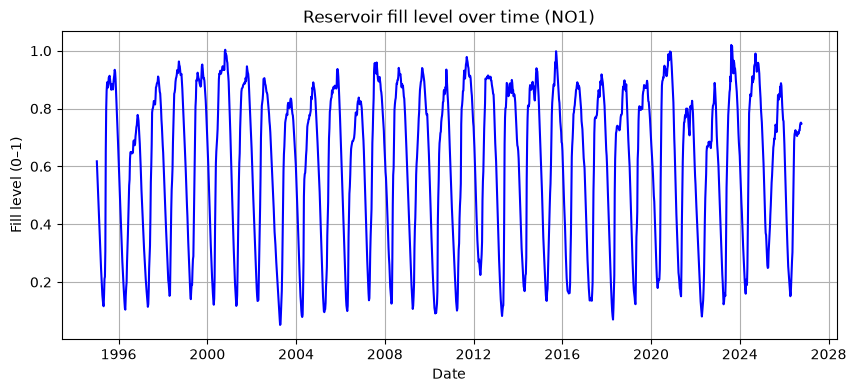

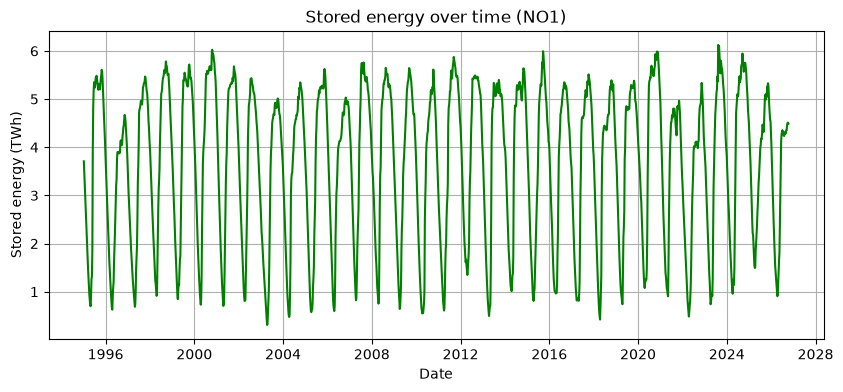

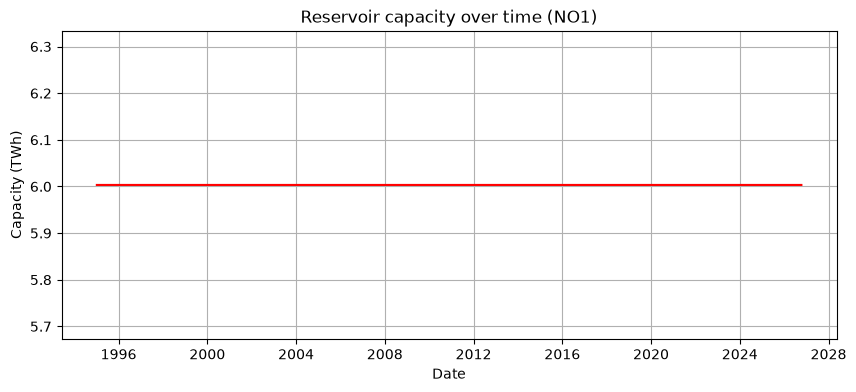

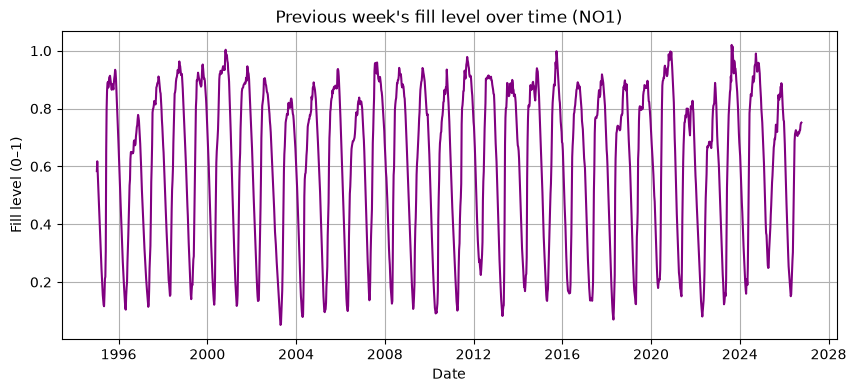

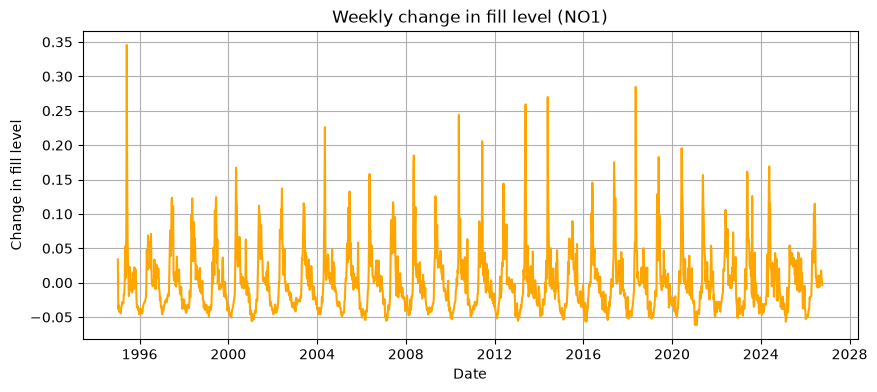

In [8]:
# Plotter hver variabel i en egen figur for strømprisområde NO1.
# Hver figur har tittel, aksetitler og rutenett for å gjøre den lett å lese.

# Fyllingsgrad
plt.figure(figsize=(10, 4))
plt.plot(df_plot["date"], df_plot["fill_level"], color="blue")
plt.title("Reservoir fill level over time (NO1)")
plt.xlabel("Date")
plt.ylabel("Fill level (0–1)")
plt.grid(True)
plt.show()

# Lagret energi
plt.figure(figsize=(10, 4))
plt.plot(df_plot["date"], df_plot["stored_energy_twh"], color="green")
plt.title("Stored energy over time (NO1)")
plt.xlabel("Date")
plt.ylabel("Stored energy (TWh)")
plt.grid(True)
plt.show()

# Kapasitet
plt.figure(figsize=(10, 4))
plt.plot(df_plot["date"], df_plot["capacity_twh"], color="red")
plt.title("Reservoir capacity over time (NO1)")
plt.xlabel("Date")
plt.ylabel("Capacity (TWh)")
plt.grid(True)
plt.show()

# Fyllingsgrad forrige uke
plt.figure(figsize=(10, 4))
plt.plot(df_plot["date"], df_plot["previous_week_fill_level"], color="purple")
plt.title("Previous week's fill level over time (NO1)")
plt.xlabel("Date")
plt.ylabel("Fill level (0–1)")
plt.grid(True)
plt.show()

# Endring i fyllingsgrad fra forrige uke
plt.figure(figsize=(10, 4))
plt.plot(df_plot["date"], df_plot["change_in_fill_level"], color="orange")
plt.title("Weekly change in fill level (NO1)")
plt.xlabel("Date")
plt.ylabel("Change in fill level")
plt.grid(True)
plt.show()

Plottene viser et tydelig sesongmønster: magasinene er lavest på våren og fylles raskt opp når snøen smelter, som gir de store positive toppene i ukentlig endring. Kapasiteten i NO1 er konstant på ca. 6 TWh gjennom hele perioden, så lagret energi følger samme mønster som fyllingsgraden. Fyllingsgraden forrige uke er den samme serien forskjøvet én uke, og brukes til å beregne ukentlig endring. Fyllingsgraden går så vidt over 1.0 enkelte år, noe som trolig skyldes målefeil eller avrunding.

### Fellesplott

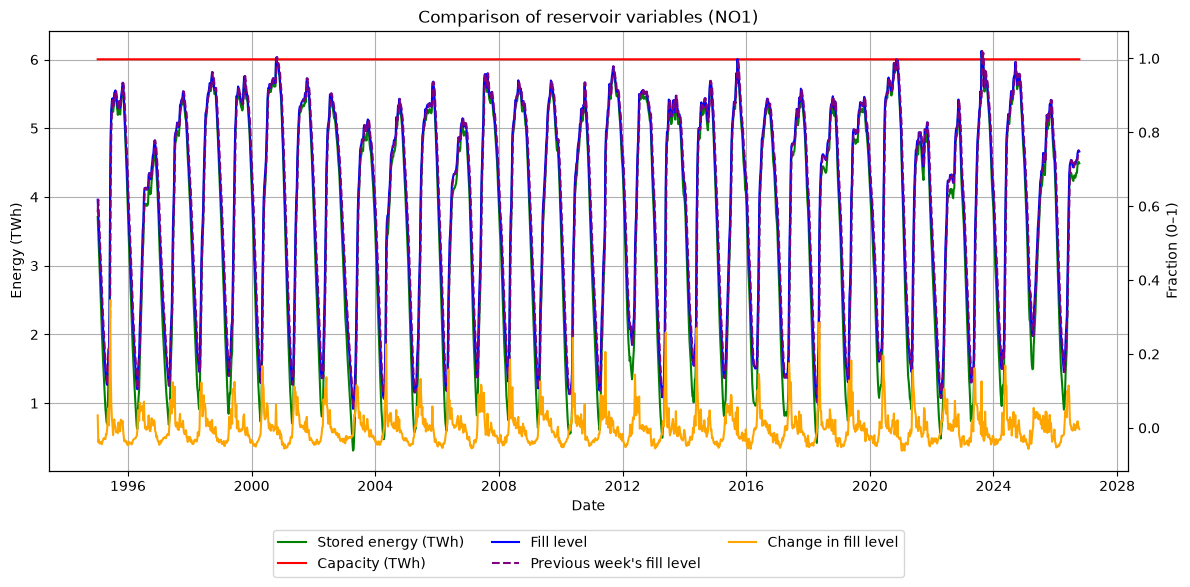

In [9]:
# Plotter alle måleverdiene i samme figur for strømprisområde NO1.
# Variablene har ulike enheter og skalaer, så de fordeles på to y-akser:
# venstre akse for energi (TWh), høyre akse for andeler (0–1).

fig, ax1 = plt.subplots(figsize=(12, 6))

# Venstre akse: variabler målt i TWh
ax1.plot(df_plot["date"], df_plot["stored_energy_twh"], color="green", label="Stored energy (TWh)")
ax1.plot(df_plot["date"], df_plot["capacity_twh"], color="red", label="Capacity (TWh)")
ax1.set_xlabel("Date")
ax1.set_ylabel("Energy (TWh)")
ax1.grid(True)

# Høyre akse: variabler som er andeler (fyllingsgrad og endring)
ax2 = ax1.twinx()
ax2.plot(df_plot["date"], df_plot["fill_level"], color="blue", label="Fill level")
ax2.plot(df_plot["date"], df_plot["previous_week_fill_level"], 
         color="purple", linestyle="--", label="Previous week's fill level")
ax2.plot(df_plot["date"], df_plot["change_in_fill_level"], 
         color="orange", label="Change in fill level")
ax2.set_ylabel("Fraction (0–1)")

# Samler linjene og navnene fra begge aksene, slik at de kan vises i én felles forklaring
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

# Legger forklaringen under plottet, slik at den ikke dekker dataene
ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),   # plasserer boksen midt under figuren
    ncol=3,                        # fordeler navnene på tre kolonner
)

plt.title("Comparison of reservoir variables (NO1)")
plt.tight_layout()
plt.show()

### Sammenligning av skalaer

Variablene har ulike enheter og skalaer. Lagret energi og kapasitet måles i TWh (ca. 0–6 for NO1), mens fyllingsgrad og endring i fyllingsgrad er andeler mellom ca. -0.1 og 1. På én felles akse ville andelene blitt nesten flate. Derfor bruker jeg to y-akser: TWh på venstre side og andeler på høyre side.

Lagret energi og fyllingsgrad ligger nesten oppå hverandre fordi kapasiteten er konstant. Lagret energi er da bare fyllingsgraden ganget med 6 TWh. Ukentlig endring viser tydelige topper hver vår, når snøsmeltingen fyller magasinene.

## Cassandra

In [10]:
from cassandra.cluster import Cluster

# Kobler til Cassandra som kjører lokalt på maskinen (standardport 9042)
cluster = Cluster(["localhost"], port=9042)
session = cluster.connect()

# Spør Cassandra om versjonsnummeret sitt, for å teste at koblingen virker
row = session.execute("SELECT release_version FROM system.local").one()
print("Koblet til Cassandra, versjon:", row.release_version)

Koblet til Cassandra, versjon: 5.0.9


In [11]:
# En keyspace i Cassandra er som en database. Den samler tabellene for prosjektet.
# SimpleStrategy med replication_factor 1 passer når Cassandra kjører på én maskin.
session.execute("""
    CREATE KEYSPACE IF NOT EXISTS ind320
    WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1}
""")

# En liten testtabell for å sjekke at Spark kan skrive og lese
session.execute("""
    CREATE TABLE IF NOT EXISTS ind320.test (
        id int PRIMARY KEY,
        name text
    )
""")
print("Keyspace og testtabell er klare")

Keyspace og testtabell er klare


In [12]:
import os
import sys
import subprocess
from pyspark.sql import SparkSession

# Forteller Spark hvor Java 17 er installert. java_home finner stien automatisk.
os.environ["JAVA_HOME"] = subprocess.check_output(
    ["/usr/libexec/java_home", "-v", "17"]
).decode().strip()

# Sørger for at Spark bruker samme Python som notebooken (.venv)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Starter Spark med Cassandra-connectoren.
# Første gang lastes connectoren ned fra internett, så det tar litt tid.
spark = (
    SparkSession.builder
    .appName("IND320")
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.cassandra.connection.host", "localhost")
    .config("spark.cassandra.connection.port", "9042")
    .getOrCreate()
)

# Viser bare feilmeldinger fra Spark, ikke alle advarslene
spark.sparkContext.setLogLevel("ERROR")

# Skriver to testrader fra Spark til Cassandra
df_test = spark.createDataFrame([(1, "first"), (2, "second")], ["id", "name"])
df_test.write.format("org.apache.spark.sql.cassandra") \
    .options(table="test", keyspace="ind320").mode("append").save()

# Leser radene tilbake fra Cassandra med Spark
spark.read.format("org.apache.spark.sql.cassandra") \
    .options(table="test", keyspace="ind320").load().show()

:: loading settings :: url = jar:file:/Users/kaja/Projects/ind320-dashboard-kaja321/.venv/lib/python3.11/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /Users/kaja/.ivy2/cache
The jars for the packages stored in: /Users/kaja/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-a030b40b-9907-4f93-b18b-63d432ce1c02;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.5.1 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.5.1 in central
	found org.scala-lang.modules#scala-collection-compat_2.12;2.11.0 in central
	found org.apache.cassandra#java-driver-core-shaded;4.18.1 in central
	found com.datastax.oss#native-protocol;1.5.1 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in central
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhistogram#HdrHistogram;2.1.12 in central
	found org.reactivestreams#reactive-streams;1.0.3

+---+------+
| id|  name|
+---+------+
|  1| first|
|  2|second|
+---+------+



Cassandra er databasen der dataene lagres lokalt på maskinen min. I boka startes Cassandra med et program som heter Docker. Docker fungerer ikke på min Mac fordi den er for gammel (MacBook Air fra 2017). Jeg installerte derfor Cassandra rett på maskinen i stedet. Både Cassandra og Spark trenger Java for å kjøre, så jeg installerte Java 17 først.

Spark er verktøyet som henter og behandler data fra Cassandra. For å teste at de to kan snakke sammen, lager jeg en liten testtabell, skriver to rader inn i Cassandra med Spark, og leser dem ut igjen.

## MongoDB

In [13]:
import tomllib
from pymongo import MongoClient

# Leser hemmelighetene fra secrets.toml, som ikke ligger på GitHub
with open(".streamlit/secrets.toml", "rb") as f:
    secrets = tomllib.load(f)

# Kobler til MongoDB Atlas med adressen fra fila
client = MongoClient(secrets["mongo"]["uri"])

# "ping" er en enkel test som bare spør om databasen svarer
client.admin.command("ping")
print("Koblet til MongoDB")

Koblet til MongoDB


In [14]:
# Velger database og samling (collection). En samling i MongoDB tilsvarer en tabell.
# Begge opprettes automatisk første gang noe lagres der.
db = client["ind320"]
test_collection = db["test"]

# Setter inn et testdokument. Et dokument i MongoDB er som en dictionary i Python.
test_collection.insert_one({"name": "test", "value": 1})

# Endrer verdien i dokumentet
test_collection.update_one({"name": "test"}, {"$set": {"value": 2}})

# Leser dokumentet tilbake. Skal nå vise value: 2.
print("Etter endring:", test_collection.find_one({"name": "test"}, {"_id": 0}))

# Sletter testdokumentet, så databasen er ren
test_collection.delete_one({"name": "test"})
print("Antall dokumenter etter sletting:", test_collection.count_documents({}))

Etter endring: {'name': 'test', 'value': 2}
Antall dokumenter etter sletting: 0


MongoDB Atlas er en database i skyen. Her lagres de ferdige dataene som Streamlit-appen skal vise. Passordet ligger i en egen fil som ikke lastes opp til GitHub.

## ENTSO-E: kraftutveksling med utlandet

In [15]:
from entsoe import EntsoePandasClient

# Kobler til ENTSO-E med tokenet fra secrets.toml (lest inn i MongoDB-cellen over)
entsoe_client = EntsoePandasClient(api_key=secrets["entsoe"]["token"])

# Testperiode: én uke. Tidssonen må oppgis, ellers vet ikke APIet hvilken tid vi mener.
start = pd.Timestamp("2026-10-01", tz="Europe/Oslo")
end = pd.Timestamp("2026-10-08", tz="Europe/Oslo")

# Henter fysisk flyt fra NO2 (Sørvest-Norge) til DK1 (Vest-Danmark), i MW
flow_test = entsoe_client.query_crossborder_flows("NO_2", "DK_1", start=start, end=end)

print("Antall målinger:", len(flow_test))
flow_test.head(10)

Antall målinger: 672


2026-10-01 00:00:00+02:00    662.02
2026-10-01 00:15:00+02:00    666.86
2026-10-01 00:30:00+02:00    666.82
2026-10-01 00:45:00+02:00    667.03
2026-10-01 01:00:00+02:00    667.09
2026-10-01 01:15:00+02:00    666.79
2026-10-01 01:30:00+02:00    667.06
2026-10-01 01:45:00+02:00    660.90
2026-10-01 02:00:00+02:00    605.97
2026-10-01 02:15:00+02:00    647.22
Freq: 15min, dtype: float64

In [16]:
# Norges utenlandsforbindelser: (norsk prisområde, utenlandsk område)
connections = [
    ("NO_1", "SE_3"),   # Østlandet – Sverige
    ("NO_2", "DK_1"),   # Sørlandet – Danmark
    ("NO_2", "NL"),     # Sørlandet – Nederland
    ("NO_2", "DE_LU"),  # Sørlandet – Tyskland
    ("NO_2", "GB"),     # Sørlandet – Storbritannia
    ("NO_3", "SE_2"),   # Midt-Norge – Sverige
    ("NO_4", "SE_1"),   # Nord-Norge – Sverige
    ("NO_4", "SE_2"),   # Nord-Norge – Sverige
    ("NO_4", "FI"),     # Nord-Norge – Finland
]

# De siste to årene, fram til i dag
end = pd.Timestamp.now(tz="Europe/Oslo").normalize()
start = end - pd.DateOffset(years=2)

all_flows = []
for no_area, foreign_area in connections:
    # Henter begge retninger: eksport (ut av Norge) og import (inn til Norge)
    for from_area, to_area, direction in [(no_area, foreign_area, "export"),
                                          (foreign_area, no_area, "import")]:
        flow = entsoe_client.query_crossborder_flows(from_area, to_area, start=start, end=end)

        # Fra kvartersverdier til timesgjennomsnitt (MW per time = MWh)
        df_flow = flow.resample("h").mean().reset_index()
        df_flow.columns = ["time", "flow_mw"]

        # Lagrer tiden i UTC uten tidssone, slik Cassandra og Spark håndterer tid
        df_flow["time"] = df_flow["time"].dt.tz_convert(None)

        df_flow["connection"] = no_area + "-" + foreign_area
        df_flow["from_area"] = from_area
        df_flow["to_area"] = to_area
        df_flow["direction"] = direction
        all_flows.append(df_flow)
        print("Hentet", from_area, "->", to_area, ":", len(df_flow), "timer")

# Slår sammen alle forbindelsene til én tabell
df_flows = pd.concat(all_flows, ignore_index=True)
print("Totalt antall rader:", len(df_flows))
df_flows.head()

Hentet NO_1 -> SE_3 : 17520 timer
Hentet SE_3 -> NO_1 : 17520 timer
Hentet NO_2 -> DK_1 : 17520 timer
Hentet DK_1 -> NO_2 : 17520 timer
Hentet NO_2 -> NL : 17520 timer
Hentet NL -> NO_2 : 17520 timer
Hentet NO_2 -> DE_LU : 17520 timer
Hentet DE_LU -> NO_2 : 17520 timer
Hentet NO_2 -> GB : 17520 timer
Hentet GB -> NO_2 : 17520 timer
Hentet NO_3 -> SE_2 : 17520 timer
Hentet SE_2 -> NO_3 : 17520 timer
Hentet NO_4 -> SE_1 : 17520 timer
Hentet SE_1 -> NO_4 : 17520 timer
Hentet NO_4 -> SE_2 : 17520 timer
Hentet SE_2 -> NO_4 : 17520 timer
Hentet NO_4 -> FI : 17520 timer
Hentet FI -> NO_4 : 17520 timer
Totalt antall rader: 315360


,time,flow_mw,connection,from_area,to_area,direction
0,2024-10-14 22:00:00,0.0,NO_1-SE_3,NO_1,SE_3,export
1,2024-10-14 23:00:00,0.0,NO_1-SE_3,NO_1,SE_3,export
2,2024-10-15 00:00:00,0.0,NO_1-SE_3,NO_1,SE_3,export
3,2024-10-15 01:00:00,0.0,NO_1-SE_3,NO_1,SE_3,export
4,2024-10-15 02:00:00,0.0,NO_1-SE_3,NO_1,SE_3,export


In [17]:
import os

# Lagrer en lokal kopi, så dataene ikke må hentes på nytt hvis notebooken restartes.
# No_sync står i .gitignore og lastes ikke opp til GitHub.
os.makedirs("No_sync", exist_ok=True)
df_flows.to_csv("No_sync/entsoe_flows.csv", index=False)
print("Lagret", len(df_flows), "rader")

Lagret 315360 rader


In [18]:
# Leser inn den lagrede kopien av ENTSO-E-dataene, så de ikke må hentes på nytt
df_flows = pd.read_csv("No_sync/entsoe_flows.csv", parse_dates=["time"])
print("Lest inn", len(df_flows), "rader")
df_flows.head()

Lest inn 315360 rader


,time,flow_mw,connection,from_area,to_area,direction
0,2024-10-14 22:00:00,0.0,NO_1-SE_3,NO_1,SE_3,export
1,2024-10-14 23:00:00,0.0,NO_1-SE_3,NO_1,SE_3,export
2,2024-10-15 00:00:00,0.0,NO_1-SE_3,NO_1,SE_3,export
3,2024-10-15 01:00:00,0.0,NO_1-SE_3,NO_1,SE_3,export
4,2024-10-15 02:00:00,0.0,NO_1-SE_3,NO_1,SE_3,export


### Lagring i Cassandra med Spark

In [19]:
# Starter med en tom tabell hver gang, så gamle rader ikke blandes med nye
session.execute("DROP TABLE IF EXISTS ind320.flows;")

# Lager en tabell for kraftflyten i keyspacet ind320
# Primærnøkkelen (connection, direction, time) er unik for hver rad:
# én måling per forbindelse, retning og time.
session.execute("""
    CREATE TABLE IF NOT EXISTS ind320.flows (
        connection text,
        direction text,
        time timestamp,
        from_area text,
        to_area text,
        flow_mw double,
        PRIMARY KEY (connection, direction, time)
    );
""")
print("Tabellen flows er klar")

Tabellen flows er klar


In [21]:
import time

# Får Python til å bruke UTC i stedet for Macens norske tid,
# slik at tidene ikke flyttes rundt overgangen til sommertid
os.environ["TZ"] = "UTC"
time.tzset()

# Tidene i df_flows er i UTC. Uten denne linja tolker Spark dem som norsk tid,
# og timene rundt overgangen til sommertid blir feil.
spark.conf.set("spark.sql.session.timeZone", "UTC")

# Skriver til Cassandra i et roligere tempo, så Cassandra ikke blir overbelastet
# på en maskin med lite minne
spark.conf.set("spark.cassandra.output.concurrent.writes", "1")
spark.conf.set("spark.cassandra.output.batch.size.rows", "100")

# Gjør om pandas-tabellen til en Spark DataFrame og lagrer den i Cassandra (append)
spark.createDataFrame(df_flows).write.format("org.apache.spark.sql.cassandra")\
    .options(table="flows", keyspace="ind320").mode("append").save()

# Sjekker at alle radene kom inn ved å telle dem med Spark
antall = spark.read.format("org.apache.spark.sql.cassandra")\
    .options(table="flows", keyspace="ind320").load().count()
print("Antall rader i Cassandra:", antall)

Antall rader i Cassandra: 315360


### Uttrekk av kolonner med Spark

In [22]:
# Leser tabellen fra Cassandra og lager et view, slik at vi kan bruke SQL
spark.read.format("org.apache.spark.sql.cassandra")\
    .options(table="flows", keyspace="ind320").load()\
    .createOrReplaceTempView("flows_view")

# Henter bare kolonnene vi trenger videre, og gjør resultatet om til en pandas-tabell
df_extracted = spark.sql("""
    SELECT connection, direction, time, flow_mw
    FROM flows_view
""").toPandas()

print("Antall rader hentet ut:", len(df_extracted))
df_extracted.head()

Antall rader hentet ut: 315360


,connection,direction,time,flow_mw
0,NO_2-DE_LU,export,2024-10-14 22:00:00,1352.48
1,NO_2-DE_LU,export,2024-10-14 23:00:00,1271.00
2,NO_2-DE_LU,export,2024-10-15 00:00:00,1323.60
3,NO_2-DE_LU,export,2024-10-15 01:00:00,1363.40
4,NO_2-DE_LU,export,2024-10-15 02:00:00,1375.60


### Plott av kraftutvekslingen

direction
export    7.787855
import    0.766715
Name: flow_mw, dtype: float64


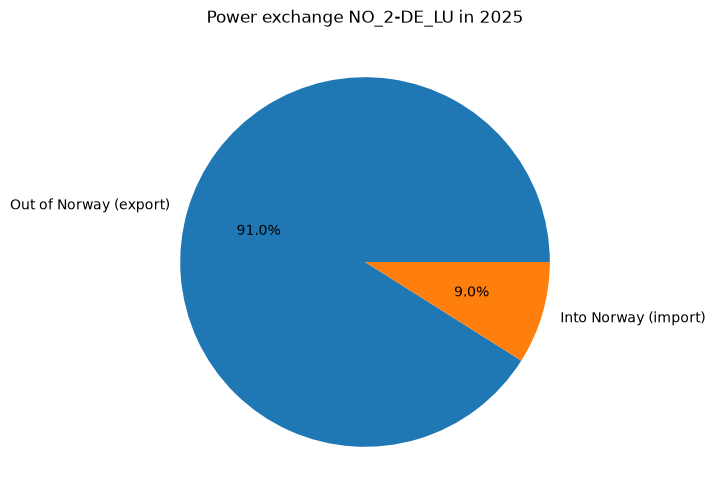

In [23]:
# Velger forbindelse og år. Kan endres til en annen forbindelse eller et annet år.
chosen_connection = "NO_2-DE_LU"   # Sørlandet – Tyskland (NordLink)
chosen_year = 2025

# Plukker ut radene for valgt forbindelse og år
df_year = df_extracted[(df_extracted["connection"] == chosen_connection) &
                       (df_extracted["time"].dt.year == chosen_year)]

# Summerer timesverdiene for hver retning. Hver time i MW tilsvarer MWh,
# og ved å dele på 1 000 000 får vi TWh.
totals = df_year.groupby("direction")["flow_mw"].sum() / 1_000_000
print(totals)

# Sektordiagram der hver bit er mengden ut av og inn til Norge
plt.figure(figsize=(6, 6))
plt.pie(totals, labels=["Out of Norway (export)", "Into Norway (import)"],
        autopct="%1.1f%%")
plt.title(f"Power exchange {chosen_connection} in {chosen_year}")
plt.show()

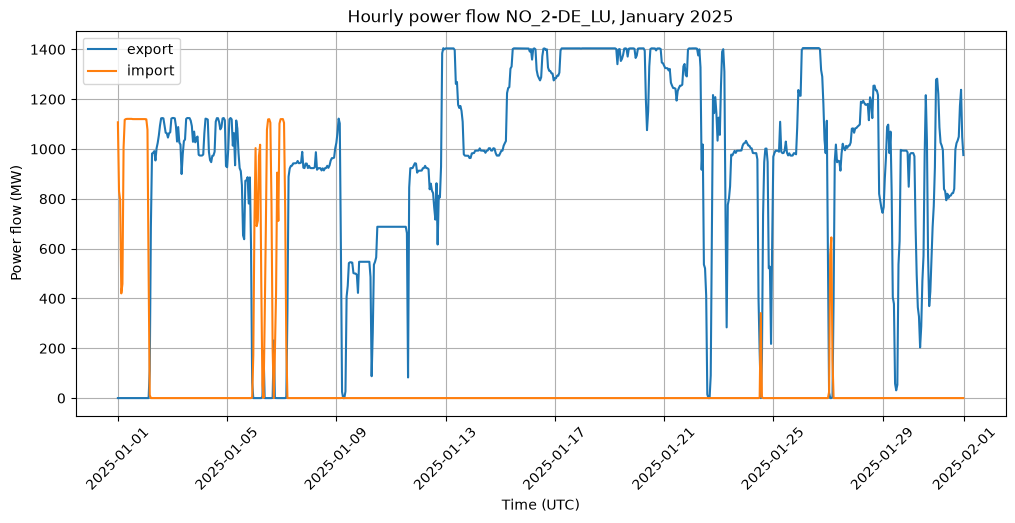

In [24]:
# Plukker ut januar i valgt år for valgt forbindelse, sortert etter tid
df_month = df_extracted[(df_extracted["connection"] == chosen_connection) &
                        (df_extracted["time"].dt.year == chosen_year) &
                        (df_extracted["time"].dt.month == 1)].sort_values("time")

# Én linje for hver retning
plt.figure(figsize=(12, 5))
for direction in ["export", "import"]:
    df_dir = df_month[df_month["direction"] == direction]
    plt.plot(df_dir["time"], df_dir["flow_mw"], label=direction)

plt.title(f"Hourly power flow {chosen_connection}, January {chosen_year}")
plt.xlabel("Time (UTC)")
plt.ylabel("Power flow (MW)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)   # skrår datoene, så de ikke overlapper
plt.show()

Sektordiagrammet viser at det meste av strømmen på NordLink (NO2–Tyskland) i 2025 gikk ut av Norge. Norge eksporterer mye strøm til Tyskland fordi vannkraften kan produsere når prisene er høye der. Linjeplottet for januar viser at strømmen bare går én vei om gangen. Eksporten ligger ofte på rundt 1400 MW, som er maksimal kapasitet på kabelen. I noen korte perioder snur flyten, og Norge importerer strøm fra Tyskland.

### Lagring i MongoDB

In [25]:
# Velger samlingen (collection) "flows" i databasen ind320 i MongoDB
flows_collection = db["flows"]

# Tømmer samlingen først, så dataene ikke dobles hvis cellen kjøres flere ganger
flows_collection.delete_many({})

# Gjør om tabellen til en liste med dictionaries (ett dokument per rad) og setter dem inn
flows_collection.insert_many(df_extracted.to_dict("records"))

print("Antall dokumenter i MongoDB:", flows_collection.count_documents({}))

Antall dokumenter i MongoDB: 315360


In [26]:
# Stopper Spark når analysen er ferdig
spark.stop()